| Symbol | Betydning i din model |
|---|---|
| x = [x₁, x₂] | Ét punkts to inputtal; ikke en label |
| y | Punktets kendte label, 0 eller 1 |
| w = [w₁, w₂] | Vægte, der bestemmer inputtenes bidrag |
| b | Bias, et ekstra tal som flytter grænsen |
| z | Vægtet sum: w₁·x₁ + w₂·x₂ + b |
| ŷ | Prediction: 1 når z ≥ 0, ellers 0. Præcis nul giver altså 1 |
| e | Fejl til opdateringen: y − ŷ; kan være −1, 0 eller 1 |
| η (eta) | Learning rate: en positiv størrelse på ændringen |

Grunddata X: (6, 2) y: (6,)


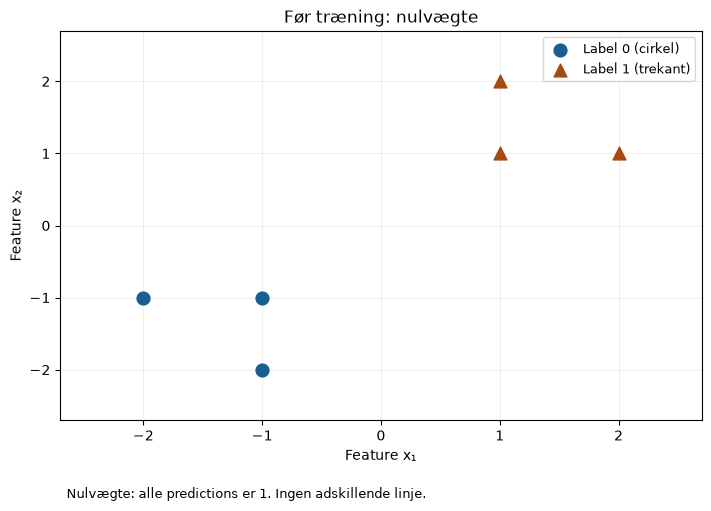

Startkontrol OK. Fortsæt til Håndregning; der er endnu ikke trænet en model.


In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from ml_support import (load_data, validate_point, validate_training, record_step,
                        show_trace, plot_boundary, plot_trace_states, save_run)
from ml_checks import check_training, check_training_result, check_inference

X_base, y_base = load_data("lineaer")
X_control, y_control = load_data("kontrol")
# Grunddata bevares; forsøgsafsnittet får egne kopier.
X_base.setflags(write=False)
y_base.setflags(write=False)
print("Grunddata X:", X_base.shape, "y:", y_base.shape)
plot_boundary(X_base, y_base, np.zeros(2), 0., title="Før træning: nulvægte")
plt.show()
print("Startkontrol OK. Fortsæt til Håndregning; der er endnu ikke trænet en model.")

### Egen prediction

Skriv `predict_one(x, w, b)`. Returnér `(score, prediction)`, hvor score er et float-tal og prediction er heltallet 0 eller 1. x og w er hver to tal, fx `[2., 1.]`; b er ét tal. Den givne første linje kontrollerer formen og giver kopier. Skriv derefter selv beregningen; beregn vægtet sum og beslutning. Der skal hverken læses en label eller ændres parametre i denne funktion.

Eksempel: z = (0.5 * 2) + (1 * -1) - 0 -> ŷ=1 -> e = (0-1) = -1

In [3]:
def predict_one(x, w, b):
    x, w, b = validate_point(x, w, b)

    score = np.dot(x, w) + b
    if score >= 0:
        prediction = 1
    else: 
        prediction = 0
    
    return score, prediction

score, prediction = predict_one(np.array([2., 1.]), np.array([.5, -1.]), 0.)
assert np.isclose(score, 0.), "Se på de to produkter og bias."
assert prediction == 1, "Præcis nul skal give label 1."
assert predict_one([0., 0.], [1., 1.], -0.2)[1] == 0
print("Prediction-kontroller OK. Fortsæt til Opdatering.")

Prediction-kontroller OK. Fortsæt til Opdatering.


### 4. Egen opdatering
**Gennemregnet opdatering (lektion 3):** Brug undervisningseksemplet x=[2, −1], w=[0.1, 0.2], b=−0.1 og y=1. Det giver z=−0.1, prediction 0 og e=1. Sæt η=0.1.

Reglen er **w_ny = w + η·e·x** og **b_ny = b + η·e**.
Her fås w_ny=[0,3; 0,1] og b_ny=0. For samme punkt er den nye sum 0,5 og prediction 1. Vi har flyttet grænsen ved at bruge den kendte fejl. Hvis e=0, ændres hverken vægte eller bias.

**Fortsæt dit håndeksempel fra afsnit 2 (4 min i lektion 3):** Brug samme x=[2,1], w=[0.5,−1], b=0 og y=0. Brug din beregnede fejl til at finde de nye vægte og bias ved η=0.1. Skriv beregningen, før du implementerer opdateringen nedenfor.

**Mine nye parametre og beregning:** …

Skriv `update_one(x, y, w, b, eta=0.1)`. Brug din prediction, beregn fejl og begge nye parametre med reglen ovenfor. Returnér `(w_new, b_new)`. Inputparametrene skal bevares. Den givne kontrol afviser ukorrekte labels og learning rate.

**Hint ved uændret bias:** Har du returneret den nye bias, eller kun den gamle? **Hint ved forkert retning:** Beregn `y − prediction` manuelt. Fortegnet betyder noget.

**Nødvendigt NumPy-greb:** `0.1 * np.array([2., -1.])` giver `[0.2, -0.1]`; en skalar ganges på hvert element. `w + ændring` danner et nyt array. Bias er ét tal og har ingen featurefaktor. Brug reglen ovenfor på dine funktionsargumenter, ikke de faste tal fra eksemplet.

Oprindeligt Eksempel: z = (2 * 0.1) + (-1 * 0.2) - 0.1 -> ŷ=1 -> e = (1-0)
z = -0.1 & prediction 0 & e=1
n = (z * -1)
n = 0.1


Opdateret n eksempel:
x = [2,1], w=[0.5, -1]
w_ny = [0,5, -1] + ((0.1 * -1)) * [2, 1] 
w_ny = [0,5, -1] + (-0,1 * [2, 1])
w_ny = [0,5, -1] + [-0.2, -0.1]
w_ny = [0.3, -1.1]

b_ny = (0 + (0.1 * -1))
b_ny = - 0.1

z = (2 * 0.3) + (1 * -1.1) + (-0.1)
z = 0.6 -1.1 - 0.1
z < 0
ŷ = 0
y = 0

e = y - ŷ= -> e = (0-0)


In [8]:

"""
Reglen er **w_ny = w + η·e·x** og **b_ny = b + η·e**.
"""

def update_one(x, y, w, b, eta=0.1):
    x, w, b = validate_point(x, w, b)
    validate_training(np.array([x]), np.array([y]), eta, 1)
    
    score, prediction = predict_one(x, w, b)
    e = y - prediction

    w_new = w + eta * e * x
    b_new = b + eta * e
    
    return w_new, b_new



w0 = np.array([.1, .2])
w1, b1 = update_one([2., -1.], 1, w0, -.1, .1)
assert np.allclose(w1, [.3, .1]) and np.isclose(b1, 0.), "Sammenlign med håndregningen."
assert np.allclose(w0, [.1, .2]), "Bevar inputvægtene."
w2, b2 = update_one([2., -1.], 1, w1, b1, .1)
assert np.allclose(w2, w1) and np.isclose(b2, b1), "e=0 skal bevare parametrene."
print("Opdateringskontroller OK. Fortsæt til Træning og spor.")

Opdateringskontroller OK. Fortsæt til Træning og spor.


## 5. Egen træningsalgoritme
Prediction og opdatering virker på **ét punkt**. Nu skal du programmere den del, der gør gentagelsen til træning. En **epoke** er én hel gennemgang af alle rækker. Den næste række skal bruge de vægte og den bias, som den forrige række efterlod.

**Gennemregnet overgang mellem to punkter:** Start w=[0,0], b=0, η=0.1. Punkt [1,1] med y=0 giver z=0, prediction 1, e=−1 og derfor w=[−0.1,−0.1], b=−0.1. Næste punkt [2,1] med y=1 bruger netop disse værdier: z=−0.4, prediction 0, e=1 → w=[0.1,0], b=0. Vi nulstiller ikke mellem punkterne. Eksemplet viser én epoke med to fejl, ikke en færdig træning.

**Din algoritme – planlæg før du skriver kode:** Skriv med egne ord, hvilke oplysninger der skal leve gennem hele træningen, og hvilke der kun gælder ét punkt eller én epoke. Forklar, hvordan du kan afgøre, at alle rækker er behandlet. Du vælger selv programmets struktur inden for disse krav:

- Hvert kald begynder med nulvægte, bias 0 og en ny tom trace; inputdata bevares.
- En epoke behandler alle rækker i deres inputrækkefølge. Hver række bruger de nyeste parametre og dine egne `predict_one` og `update_one`.
- Fejl tælles ud fra prediction før opdatering. Stop efter den første hele fejlfri epoke eller senest ved `max_epochs`.
- Returnér de sidste vægte, bias og den fulde trace som `(w, b, trace)`.

**Min plan og begrundelse:** …
Vægtene w og bias b skal videreføres gennem hele træningsepoken, fordi det er justeringsparametrene, som forsøger at korrigere algoritmen til at forudse de rigtige værdier efter hvert punkt. Eta forbliver den samme, medmindre argumentet ændres.
X og y er de enkelte datapunkter, og skal derfor ikke videreføres som en del af modellens 'state'. Det samme med score, prediction og error, som jo også kun er gældende for den enkelte række. 
'
For hver epoke går koden igennem alle rækker. Koden tæller fejlen ud fra prediction før opdateringen. Når epokens rækker er behandlet, kan det ses hvorvidt der blev dokumenteres fejl i algorithmens forudsigelser. Hvis der ikke dokumeneteres nogle fejl, stopper træningen automatisk. 


Du skriver selv løkker, initialisering, parameteroverførsel, fejltælling og stop. Inputvalideringen er givet. Ved behov kan du bruge de afgrænsede hints i selvstudieguiden; der er ingen færdig algoritmeopskrift.

`record_step(...)` er **teknisk støtte**, ikke en ny datastruktur du skal designe. Brug kaldet nedenfor efter din opdatering, så trace gemmer de værdier, din algoritme faktisk beregnede:

```python
record_step(
    trace, epoch=epoch, row=row, score=score,
    prediction=prediction, error=error,
    w_before=w_before, b_before=b_before, w_after=w, b_after=b,
)
```

**Trace-konvention:** `epoch` starter ved 1, `row` ved 0. Registrér alle rækker, også dem uden fejl. `record_step` udfylder formatet ud fra dine værdier.

**Vigtigt:**
- Score, prediction og error skal beskrive tilstanden **før** opdateringen.
- `w_before` skal være en kopi, ellers kan senere ændringer gøre dit spor misvisende.
- Et enkelt korrekt punkt stopper ikke træningen. Stop først efter en **hel epoke** uden fejl.
- Et nyt kald til `train` starter igen fra nulparametre.

Efter definitionen kører du den givne `check_training(train)`. Den kontrollerer blandt andet begge punkter ovenfor, learning rate, videreført state og stop efter en fejlfri epoke. Kontrollen er feedback på din algoritme; den erstatter ikke din egen forklaring.

In [ ]:
def train(X, y, eta=0.1, max_epochs=50):
    # Givet teknisk indgang: kontrollér og kopiér input.
    X, y = validate_training(X, y, eta, max_epochs)

    # TODO: Skriv din træningsalgoritme efter kravene i afsnit 5.
    w = [0, 0]
    b = 0
    trace = []

    for epoch in range(1, max_epochs + 1):
        errors = 0
    
        for row in range(len(X)):
            
            w_before = w.copy()
            b_before = b

            current_x = X[row]
            current_y = y[row]

            score, prediction = predict_one(current_x, w, b)

            error = (current_y - prediction)
            
            if error != 0:
                errors += 1

            w, b = update_one(current_x, current_y, w, b, eta)
            
            record_step(
            trace, epoch=epoch, row=row, score=score,
            prediction=prediction, error=error,
            w_before=w_before, b_before=b_before, w_after=w, b_after=b,
            )

        if errors != 0:
            continue  

        else:
            break
    
    return w, b, trace      

Løkkekontroller OK: rækkegennemgang, to opdateringer, state, learning rate og stop i de afgrænsede prøver.
Fortsæt til dit grundforsøg. Kontrollerne erstatter ikke din traceforklaring eller afprøvning på andre data.
epoke 1, række 0: z=0, pred=1, e=-1; w [0, 0] → [0.2, 0.1]; b 0 → -0.1
epoke 1, række 1: z=-0.5, pred=0, e=0; w [0.2, 0.1] → [0.2, 0.1]; b -0.1 → -0.1
epoke 1, række 2: z=-0.4, pred=0, e=0; w [0.2, 0.1] → [0.2, 0.1]; b -0.1 → -0.1
epoke 1, række 3: z=0.2, pred=1, e=0; w [0.2, 0.1] → [0.2, 0.1]; b -0.1 → -0.1
epoke 1, række 4: z=0.4, pred=1, e=0; w [0.2, 0.1] → [0.2, 0.1]; b -0.1 → -0.1
epoke 1, række 5: z=0.3, pred=1, e=0; w [0.2, 0.1] → [0.2, 0.1]; b -0.1 → -0.1
epoke 2, række 0: z=-0.6, pred=0, e=0; w [0.2, 0.1] → [0.2, 0.1]; b -0.1 → -0.1
epoke 2, række 1: z=-0.5, pred=0, e=0; w [0.2, 0.1] → [0.2, 0.1]; b -0.1 → -0.1
Grundforsøg: {'epochs': 2, 'steps': 12, 'errors_per_epoch': [1, 0]}


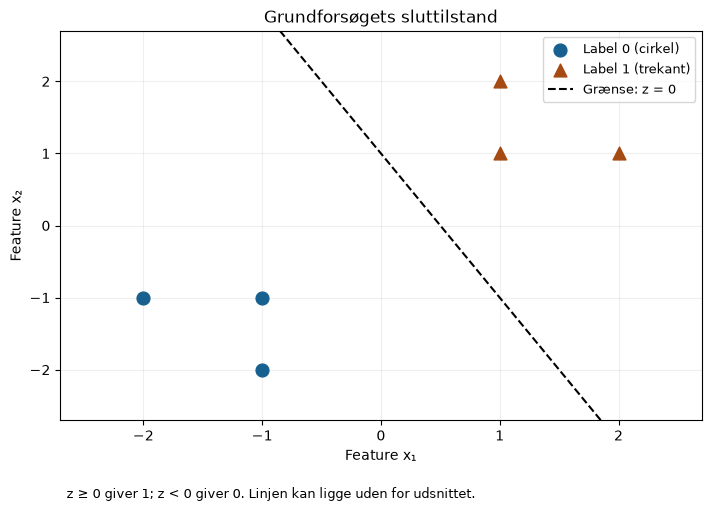

Gemt i output\grund: resultat.json (data, parametre og trace) og slutgraense.png.
Grundforsøget er gemt. Forklar ét trace-trin, og fortsæt derefter til inference.


In [14]:
check_training(train)

# Grundforsøget har egne data, parametre, trace og outputmappe.
w_base, b_base, trace_base = train(X_base, y_base, eta=0.1, max_epochs=50)
base_checks = check_training_result(X_base, y_base, w_base, b_base, trace_base)
w_base = np.asarray(w_base, dtype=float).copy()
w_base.setflags(write=False)
show_trace(trace_base)
print("Grundforsøg:", base_checks)
plot_boundary(X_base, y_base, w_base, b_base, title="Grundforsøgets sluttilstand")
plt.show()
save_run("output/grund", X_base, y_base, w_base, b_base, trace_base)
print("Grundforsøget er gemt. Forklar ét trace-trin, og fortsæt derefter til inference.")

### 6. Inference på flere punkter
Under træning bruger du kendte labels til at beregne fejl og ændre parametrene. Ved **inference** bruger du derimod de færdige parametre til predictions uden at ændre modellen.

Skriv `predict_many(X, w, b)`, som bruger din `predict_one` på hver række i `X` og returnerer et NumPy-array med predictions. Formkontrollen er givet. Brug en almindelig løkke, så du tydeligt kan pege på, at `w` og `b` kun bliver læst.

Når funktionen virker, anvender du den på `X_control`. Den givne kontrol afprøver håndberegnede svar, ændret rækkeorden, forskellige parametre og uændrede input. Den er en afgrænset funktionskontrol; forklar også, hvorfor din kode ikke opdaterer modellen. **Inference må ikke ændre dem.**

In [ ]:
def predict_many(X, w, b):
    # Givet teknisk kontrol af inputformen.
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != 2:
        raise ValueError("X skal have shape (n, 2).")

    # TODO: Brug predict_one på hver række og returnér alle predictions.
    for row in X:
        score, prediction = predict_one(X, w, b)
        


        
    raise NotImplementedError("TODO inference: loop over X og saml predictions. Se afsnit 6.")

In [ ]:
check_inference(predict_many)
predictions_base = predict_many(X_control, w_base, b_base)
print("Grundforsøgets kontrol:", predictions_base, "kendte labels:", y_control)
print("Forklar, hvordan din funktion bruger de færdige parametre uden opdatering.")